In [ ]:
# NERAM supervisory controller - complete Colab version (single cell)
# Fixes vs your earlier draft: real FaultMonitor (not a stub), closed-loop
# plant (Heat now actually affects T_est), overtemp + sensor-fault demos.
# Paste this WHOLE cell into Colab and run it. No PyCharm/MATLAB needed.
import numpy as np, csv, os
import matplotlib.pyplot as plt

# ===== from params.py =====

P = dict(
    # --- timing (ts_ctrl_s PROVISIONAL, ts_twin_s FROZEN) ---
    ts_ctrl_s=1,
    ts_twin_s=60,
    data_stale_twin_s=120,      # PROVISIONAL (derived), placeholder=2x ts_twin_s
    data_stale_hw_s=5,          # TBD placeholder (Shreehan)

    # --- thresholds (TBD placeholders, Sai) ---
    t_hypo_degC=36.0,           # TBD, doc-supplied placeholder (section H)
    t_target_degC=37.0,         # TBD, Claude-added placeholder (not in plan text)
    p_trigger=0.3,              # TBD placeholder
    p_release=0.2,              # TBD placeholder
    n_confirm_updates=2,        # TBD placeholder

    # --- Suchita's own design choices (PROVISIONAL, real) ---
    band_target_degC=0.3,
    t_dwell_min_s=10,
    t_recover_s=30,
    t_stop_inhibit_s=300,
    d_pred_max_pct=40,
    d_active_max_pct=70,
    d_maint_max_pct=50,
    d_fallback_pct=20,
    kp_pct_per_degC=20,
    ki_pct_per_degC_s=0.5,

    # --- Shreehan's hardware rows (TBD placeholders) ---
    p_max_ch_pct=[50, 50, 50, 50],
    t_mod_derate_degC=38,
    t_mod_trip_degC=41,
    t_mod_reset_degC=37,
    dt_sensor_disagree_degC=2.0,
    i_open_max_A=0.05,
    i_over_A=2.0,
    i_stuck_A=0.05,
    i_on_A=0.5,                 # TBD placeholder, test-bench only (nominal current at Heat=100%)

    # --- Sai's plant equation rows (TBD placeholders, test-bench only) ---
    k_heat_degC_per_h=0.6,
    tau_heat_min=15,
    w_ch=[0.25, 0.25, 0.25, 0.25],

    # --- Suchita's test-only ASSUMED stand-ins (section M.4) ---
    t_skin_base_degC=33.0,
    k_mod_degC=6.0,
    tau_mod_s=90,
    sd_mod_sensor_degC=0.05,
    sd_standin_degC=0.05,
    tau_standin_s=15,
)


# ===== from blocks.py =====

NAN = float('nan')


class TwinAdapter:
    """Section D block 1. Twin_Valid numeric: 0 NO_DATA,1 INITIALISING,2 VALID,3 DEGRADED."""

    def __init__(self, P):
        self.P = P
        self.last_T_twin_s = NAN
        self.last_update_t_s = NAN
        self.risk_confirm_count = 0
        self.risk_pred_latched = False
        self.risk_pred_leg = 0
        self.last_stop_t_s = -np.inf

    def step(self, t_s, T_twin_s, T_obs, T_est, T_est_sd, T_pred_20, T_pred_30, T_pred_60,
             P_below_hypo_20, P_below_hypo_30, P_below_hypo_60, Twin_Valid,
             Clinician_Stop_rising):
        P = self.P
        new_twin_update = np.isnan(self.last_T_twin_s) or (not np.isnan(T_twin_s) and T_twin_s != self.last_T_twin_s)
        if new_twin_update and not np.isnan(T_twin_s):
            self.last_update_t_s = t_s
            self.last_T_twin_s = T_twin_s

        Data_Stale_Twin = True if np.isnan(self.last_update_t_s) else (t_s - self.last_update_t_s) > P['data_stale_twin_s']
        twin_ok = (Twin_Valid == 2) and not Data_Stale_Twin
        twin_bad = (Twin_Valid == 3) or (Twin_Valid == 0) or Data_Stale_Twin

        if new_twin_update:
            p20_trig = (not np.isnan(P_below_hypo_20)) and P_below_hypo_20 >= P['p_trigger']
            p30_trig = (not np.isnan(P_below_hypo_30)) and P_below_hypo_30 >= P['p_trigger']
            trig_now = twin_ok and (p20_trig or p30_trig)
            rel_now = (np.isnan(P_below_hypo_20) or P_below_hypo_20 < P['p_release']) and \
                      (np.isnan(P_below_hypo_30) or P_below_hypo_30 < P['p_release'])
            if self.risk_pred_latched:
                if rel_now:
                    self.risk_pred_latched = False
                    self.risk_confirm_count = 0
                    self.risk_pred_leg = 0
            else:
                if trig_now:
                    self.risk_confirm_count += 1
                    if self.risk_pred_leg == 0:
                        self.risk_pred_leg = 1 if p20_trig else 2
                    if self.risk_confirm_count >= P['n_confirm_updates']:
                        self.risk_pred_latched = True
                else:
                    self.risk_confirm_count = 0
                    self.risk_pred_leg = 0
        risk_pred = self.risk_pred_latched
        risk60 = twin_ok and (not np.isnan(P_below_hypo_60)) and P_below_hypo_60 >= P['p_trigger']

        if np.isnan(T_est):
            below_hypo = at_target = target_lost = False
        else:
            below_hypo = T_est < P['t_hypo_degC']
            at_target = T_est >= P['t_target_degC']
            target_lost = T_est < (P['t_target_degC'] - P['band_target_degC'])

        if Clinician_Stop_rising:
            self.last_stop_t_s = t_s
        stop_inhibit = (t_s - self.last_stop_t_s) < P['t_stop_inhibit_s']

        return dict(Data_Stale_Twin=Data_Stale_Twin, twin_ok=twin_ok, twin_bad=twin_bad,
                    risk_pred=risk_pred, risk60=risk60, below_hypo=below_hypo,
                    at_target=at_target, target_lost=target_lost, stop_inhibit=stop_inhibit,
                    Trigger_Reason_hint=self.risk_pred_leg)


class FaultMonitor:
    """Section D block 2 / section L fault table. Full per-channel + system
    fault logic, faithfully ported from FaultMonitor_block.m. Channel_Fault
    codes = 100*ch + k (k=1..11); system codes 1-8 (8=DATA_STALE_HW)."""

    def __init__(self, P):
        self.P = P
        self.chan_latch = [0, 0, 0, 0]
        self.sys_latch_code = 0
        self.open_since = [NAN] * 4
        self.disagree_since = [NAN] * 4
        self.stuck_count = [0, 0, 0, 0]

    def step(self, t_s, Module_Temp_A, Module_Temp_B, Module_Connected, Heater_Current,
             HW_Cutoff, HW_Heartbeat_s, HW_Fault_Code, Heat_prev, Clinician_Reset_rising):
        P = self.P
        Data_Stale_HW = np.isnan(HW_Heartbeat_s) or (t_s - HW_Heartbeat_s) > P['data_stale_hw_s']

        for i in range(4):
            A, B = Module_Temp_A[i], Module_Temp_B[i]
            A_bad, B_bad = np.isnan(A), np.isnan(B)
            code_now = 0

            if A_bad and B_bad:
                code_now = 100 * (i + 1) + 3
            elif A_bad:
                code_now = 100 * (i + 1) + 1
            elif B_bad:
                code_now = 100 * (i + 1) + 2
            else:
                if abs(A - B) > P['dt_sensor_disagree_degC']:
                    if np.isnan(self.disagree_since[i]):
                        self.disagree_since[i] = t_s
                    if (t_s - self.disagree_since[i]) >= P['t_dwell_min_s']:
                        code_now = 100 * (i + 1) + 5
                else:
                    self.disagree_since[i] = NAN

            T_mod = max(A, B) if not (A_bad or B_bad) else NAN
            if not A_bad and not B_bad and T_mod >= P['t_mod_trip_degC']:
                code_now = 100 * (i + 1) + 6
            if HW_Cutoff[i]:
                code_now = 100 * (i + 1) + 7
            if not Module_Connected[i]:
                code_now = 100 * (i + 1) + 8

            Icur, Hprev = Heater_Current[i], Heat_prev[i]
            if not np.isnan(Icur):
                if Hprev > 0 and Icur < P['i_open_max_A']:
                    if np.isnan(self.open_since[i]):
                        self.open_since[i] = t_s
                    if (t_s - self.open_since[i]) >= P['t_dwell_min_s']:
                        code_now = 100 * (i + 1) + 9
                else:
                    self.open_since[i] = NAN
                if Icur > P['i_over_A']:
                    code_now = 100 * (i + 1) + 10
                if Hprev == 0 and Icur > P['i_stuck_A']:
                    self.stuck_count[i] += 1
                else:
                    self.stuck_count[i] = 0
                if self.stuck_count[i] >= 2:
                    code_now = 100 * (i + 1) + 11
            else:
                code_now = 100 * (i + 1) + 9

            if code_now != 0:
                self.chan_latch[i] = code_now

            if Clinician_Reset_rising:
                k = self.chan_latch[i] % 100
                still_present = False
                if k in (1, 2, 3):
                    still_present = A_bad or B_bad
                elif k == 5:
                    still_present = (not A_bad) and (not B_bad) and abs(A - B) > P['dt_sensor_disagree_degC']
                elif k == 6:
                    still_present = (not A_bad) and (not B_bad) and T_mod >= P['t_mod_reset_degC']
                elif k == 7:
                    still_present = HW_Cutoff[i]
                elif k == 8:
                    still_present = not Module_Connected[i]
                if not still_present:
                    self.chan_latch[i] = 0
                    self.open_since[i] = NAN
                    self.disagree_since[i] = NAN
                    self.stuck_count[i] = 0

        sys_shutdown_now = False
        sys_code_now = 0
        if HW_Fault_Code != 0:
            sys_shutdown_now = True
            sys_code_now = HW_Fault_Code
        if Data_Stale_HW:
            sys_shutdown_now = True
            sys_code_now = 8
        for i in range(4):
            k = self.chan_latch[i] % 100
            if k in (6, 7, 10, 11):
                sys_shutdown_now = True
                # BUGFIX (found building the overtemp/stuck-on fault demo):
                # a channel-triggered all-off shutdown (k=6/7/10/11) left
                # sys_code_now at 0, so sys_latch_code = max(0,0) stayed 0
                # and system_fault was never set True even though
                # sys_shutdown_now was True. Latch the triggering channel's
                # own code so the system-wide shutdown actually sticks.
                if sys_code_now == 0:
                    sys_code_now = self.chan_latch[i]

        if self.sys_latch_code != 0 or sys_shutdown_now:
            self.sys_latch_code = max(self.sys_latch_code, sys_code_now)

        if Clinician_Reset_rising:
            hw_clear = (HW_Fault_Code == 0)
            hw_stale_clear = not Data_Stale_HW
            all_chan_overtemp_clear = True
            no_shutdown_chan_latched = True
            for i in range(4):
                k = self.chan_latch[i] % 100
                if k == 6:
                    all_chan_overtemp_clear = False
                if k in (6, 7, 10, 11):
                    no_shutdown_chan_latched = False
            if hw_clear and hw_stale_clear and all_chan_overtemp_clear and no_shutdown_chan_latched:
                self.sys_latch_code = 0

        system_fault = self.sys_latch_code != 0
        if self.sys_latch_code != 0:
            fc = self.sys_latch_code
        else:
            fc = 0
            for i in range(4):
                if self.chan_latch[i] != 0:
                    fc = self.chan_latch[i]
                    break

        Fault_Latched = system_fault or any(c != 0 for c in self.chan_latch)
        return dict(Channel_Fault=list(self.chan_latch), system_fault=system_fault,
                    fault_code=fc, Fault_Latched=Fault_Latched, Data_Stale_HW=Data_Stale_HW)


class Supervisor:
    """Section D block 3 - STAND-IN for the real Stateflow chart (no
    Stateflow license today); same transition table T1-T14 (section J)."""

    def __init__(self, P):
        self.P = P
        self.state = 0
        self.ClinMode = False
        self.prev_Start = self.prev_Stop = self.prev_Reset = False
        self.held = dict(T5=NAN, T6=NAN, T10=NAN, T11=NAN, T12=NAN, T13=NAN, T14=NAN)

    def step(self, t_s, system_fault, twin_bad, twin_ok, risk_pred, risk60, below_hypo,
             at_target, target_lost, stop_inhibit, Trigger_Reason_hint,
             Clinician_Start, Clinician_Stop, Clinician_Reset, T_mod):
        P = self.P
        rising_Start = Clinician_Start and not self.prev_Start
        rising_Stop = Clinician_Stop and not self.prev_Stop
        rising_Reset = Clinician_Reset and not self.prev_Reset
        self.prev_Start, self.prev_Stop, self.prev_Reset = Clinician_Start, Clinician_Stop, Clinician_Reset

        prev_state = self.state
        reset_blocked_now = False
        stop_ack_now = False
        Trigger_Reason = 0
        h = self.held

        if self.state != 7 and system_fault:
            self.state = 7
            Trigger_Reason = 8
        elif self.state == 7:
            if rising_Reset:
                all_cool = all(np.isnan(t) or t < P['t_mod_reset_degC'] for t in T_mod)
                if not system_fault and all_cool:
                    self.state = 0
                    self.ClinMode = False
                    Trigger_Reason = 11
                else:
                    reset_blocked_now = True
        else:
            is_warming = self.state in (1, 2, 3, 4, 6)
            if rising_Stop and is_warming:
                self.state = 0
                self.ClinMode = False
                Trigger_Reason = 7
                stop_ack_now = True
            elif twin_bad and self.state not in (5, 6):
                self.state = 6 if self.ClinMode else 5
                Trigger_Reason = 9
            elif self.state == 5:
                h['T5'] = t_s if (twin_ok and np.isnan(h['T5'])) else (h['T5'] if twin_ok else NAN)
                held5 = (not np.isnan(h['T5'])) and (t_s - h['T5']) >= P['t_recover_s']
                if rising_Start:
                    self.state = 6
                    Trigger_Reason = 4
                elif held5:
                    self.state = 0
                    Trigger_Reason = 10
            elif self.state == 6:
                h['T6'] = t_s if (twin_ok and np.isnan(h['T6'])) else (h['T6'] if twin_ok else NAN)
                held6 = (not np.isnan(h['T6'])) and (t_s - h['T6']) >= P['t_recover_s']
                if held6:
                    self.state = 4
                    Trigger_Reason = 10
            elif self.state == 0:
                if rising_Start and twin_ok:
                    self.state = 4
                    self.ClinMode = True
                    Trigger_Reason = 4
                elif rising_Start and not twin_ok:
                    self.state = 6
                    self.ClinMode = True
                    Trigger_Reason = 4
                else:
                    cond10 = twin_ok and below_hypo and not stop_inhibit
                    h['T10'] = t_s if (cond10 and np.isnan(h['T10'])) else (h['T10'] if cond10 else NAN)
                    ok10 = (not np.isnan(h['T10'])) and (t_s - h['T10']) >= P['t_dwell_min_s']
                    cond11 = risk_pred and not below_hypo and not stop_inhibit
                    h['T11'] = t_s if (cond11 and np.isnan(h['T11'])) else (h['T11'] if cond11 else NAN)
                    ok11 = (not np.isnan(h['T11'])) and (t_s - h['T11']) >= P['t_dwell_min_s']
                    if ok10:
                        self.state = 2
                        Trigger_Reason = 3
                    elif ok11:
                        self.state = 1
                        Trigger_Reason = 2 if Trigger_Reason_hint == 2 else 1
            elif self.state == 1:
                h['T12'] = t_s if (below_hypo and np.isnan(h['T12'])) else (h['T12'] if below_hypo else NAN)
                ok12 = (not np.isnan(h['T12'])) and (t_s - h['T12']) >= P['t_dwell_min_s']
                h['T13'] = t_s if (at_target and np.isnan(h['T13'])) else (h['T13'] if at_target else NAN)
                ok13 = (not np.isnan(h['T13'])) and (t_s - h['T13']) >= P['t_dwell_min_s']
                if ok12:
                    self.state = 2
                    Trigger_Reason = 3
                elif ok13:
                    self.state = 3
                    Trigger_Reason = 5
            elif self.state in (2, 4):
                h['T13'] = t_s if (at_target and np.isnan(h['T13'])) else (h['T13'] if at_target else NAN)
                ok13 = (not np.isnan(h['T13'])) and (t_s - h['T13']) >= P['t_dwell_min_s']
                if ok13:
                    self.state = 3
                    Trigger_Reason = 5
            elif self.state == 3:
                h['T14'] = t_s if (target_lost and np.isnan(h['T14'])) else (h['T14'] if target_lost else NAN)
                ok14 = (not np.isnan(h['T14'])) and (t_s - h['T14']) >= P['t_dwell_min_s']
                if ok14:
                    self.state = 2
                    Trigger_Reason = 6

        state_entry = (self.state != prev_state)
        if state_entry:
            for k in h:
                h[k] = NAN

        state_map = {0: (0, 0, 0), 1: (1, 0, 1), 2: (2, 0, 2), 3: (3, 0, 3),
                     4: (4, 0, 2), 5: (5, 1, 0), 6: (5, 2, 4)}
        Controller_State, Degraded_Substate, demand_mode = state_map.get(self.state, (6, 0, 0))
        Safety_Shutdown = (self.state == 7)

        if self.state == 7:
            Alert = 5
        elif reset_blocked_now:
            Alert = 8
        elif self.state in (5, 6):
            Alert = 3
        elif self.state == 1:
            Alert = 1
        elif self.state == 0 and risk60:
            Alert = 2
        elif stop_ack_now:
            Alert = 7
        else:
            Alert = 0

        return dict(Controller_State=Controller_State, Degraded_Substate=Degraded_Substate,
                    Trigger_Reason=Trigger_Reason, Alert=Alert, Safety_Shutdown=Safety_Shutdown,
                    Clinician_Mode=self.ClinMode, demand_mode=demand_mode, state_entry=state_entry)


class DemandLaw:
    """Section D block 4 - PI control with clamping anti-windup."""

    def __init__(self, P):
        self.P = P
        self.integ = 0.0

    def step(self, T_est, demand_mode, state_entry):
        P = self.P
        if state_entry:
            self.integ = 0.0
        caps = {0: 0, 1: P['d_pred_max_pct'], 2: P['d_active_max_pct'],
                3: P['d_maint_max_pct'], 4: P['d_fallback_pct']}
        cap = caps.get(demand_mode, 0)
        if demand_mode == 0:
            self.integ = 0.0
            return 0.0
        if np.isnan(T_est):
            return 0.0
        e = P['t_target_degC'] - T_est
        integ_trial = self.integ + P['ki_pct_per_degC_s'] * e * P['ts_ctrl_s']
        D_trial = P['kp_pct_per_degC'] * e + integ_trial
        D = max(0, min(cap, D_trial))
        if 0 <= D_trial <= cap:
            self.integ = integ_trial
        return D


def channel_limiter(P, D, Channel_Fault, Module_Connected, HW_Cutoff, Safety_Shutdown,
                     Module_Temp_A, Module_Temp_B):
    """Section D block 5 - vectorized over 4 channels, no persistent state."""
    Heat = [0.0] * 4
    for i in range(4):
        faulted = Channel_Fault[i] != 0
        disconnected = not Module_Connected[i]
        cutoff = HW_Cutoff[i]
        enable = not (faulted or disconnected or cutoff or Safety_Shutdown)
        Tmod = max(Module_Temp_A[i], Module_Temp_B[i])
        if np.isnan(Tmod):
            derate = 0
        elif Tmod <= P['t_mod_derate_degC']:
            derate = 1
        elif Tmod >= P['t_mod_trip_degC']:
            derate = 0
        else:
            derate = (P['t_mod_trip_degC'] - Tmod) / (P['t_mod_trip_degC'] - P['t_mod_derate_degC'])
        Heat[i] = enable * min(D, P['p_max_ch_pct'][i] * derate)
        Heat[i] = max(0, min(Heat[i], P['p_max_ch_pct'][i]))
    return Heat


class Controller:
    """Wires all 5 blocks together in order, exactly as neram_controller.slx
    will (section D/F): TwinAdapter + FaultMonitor -> Supervisor -> DemandLaw
    -> ChannelLimiter. One .step() = one 1 s control tick."""

    def __init__(self, P):
        self.P = P
        self.twin = TwinAdapter(P)
        self.fault = FaultMonitor(P)
        self.sup = Supervisor(P)
        self.dem = DemandLaw(P)
        self.Heat_prev = [0, 0, 0, 0]
        self.prev_Clinician_Stop = 0

    def step(self, t_s, sig):
        """sig is a dict with every input signal name (section E) for this tick."""
        P = self.P
        ot = self.twin.step(
            t_s, sig['T_twin_s'], sig['T_obs'], sig['T_est'], sig['T_est_sd'],
            sig['T_pred_20'], sig['T_pred_30'], sig['T_pred_60'],
            sig['P_below_hypo_20'], sig['P_below_hypo_30'], sig['P_below_hypo_60'],
            sig['Twin_Valid'], sig['Clinician_Stop'] and not self.prev_Clinician_Stop)
        self.prev_Clinician_Stop = sig['Clinician_Stop']

        of = self.fault.step(
            t_s, sig['Module_Temp_A'], sig['Module_Temp_B'], sig['Module_Connected'],
            sig['Heater_Current'], sig['HW_Cutoff'], sig['HW_Heartbeat_s'],
            sig['HW_Fault_Code'], self.Heat_prev, sig['Clinician_Reset'])

        T_mod = [max(a, b) for a, b in zip(sig['Module_Temp_A'], sig['Module_Temp_B'])]
        os_ = self.sup.step(
            t_s, of['system_fault'], ot['twin_bad'], ot['twin_ok'], ot['risk_pred'],
            ot['risk60'], ot['below_hypo'], ot['at_target'], ot['target_lost'],
            ot['stop_inhibit'], ot['Trigger_Reason_hint'], sig['Clinician_Start'],
            sig['Clinician_Stop'], sig['Clinician_Reset'], T_mod)

        D = self.dem.step(sig['T_est'], os_['demand_mode'], os_['state_entry'])
        Heat = channel_limiter(P, D, of['Channel_Fault'], sig['Module_Connected'],
                                sig['HW_Cutoff'], os_['Safety_Shutdown'],
                                sig['Module_Temp_A'], sig['Module_Temp_B'])
        self.Heat_prev = Heat

        out = dict(t_s=t_s, D=D, Heat=Heat)
        out.update({f'twin_{k}': v for k, v in ot.items()})
        out.update({f'fault_{k}': v for k, v in of.items()})
        out.update({f'sup_{k}': v for k, v in os_.items()})
        return out


# ===== from testbench.py =====

NAN = float('nan')
rng = np.random.default_rng(42)


class PatientPlant:
    """ASSUMED simple first-order patient-temperature stand-in (section M.1/
    M.2 intent): without heat, settles toward a cold `baseline` (why the
    patient needs warming at all); active heat pulls it up at
    k_heat_degC_per_h. NOT a clinical/physiological model - a labelled
    stand-in only, same spirit as Suchita's module thermal stand-in.
    Passive settling is given a much longer time constant than the active
    warming response (10x tau_heat_min) so the two don't just cancel out -
    a body cools far slower passively than an active warmer can raise it."""

    def __init__(self, P, T0=35.0):
        self.P = P
        self.T = T0
        self.baseline = T0  # where T would passively settle with no heat at all
        self.tau_passive_s = P['tau_heat_min'] * 60.0 * 10

    def step(self, Heat, dt_s):
        P = self.P
        d = sum(w * h / 100 for w, h in zip(P['w_ch'], Heat))  # weighted applied heat fraction
        warm_rate_degC_per_s = P['k_heat_degC_per_h'] * d / 3600.0
        passive_pull = (self.baseline - self.T) / self.tau_passive_s
        self.T += dt_s * (warm_rate_degC_per_s + passive_pull)
        return self.T


class ModuleThermal:
    """ASSUMED per-channel warming-module thermal stand-in (section M.4),
    first-order response of module skin temp to applied Heat_i."""

    def __init__(self, P):
        self.P = P
        self.T_mod = [P['t_skin_base_degC']] * 4

    def step(self, Heat, dt_s):
        P = self.P
        out_A, out_B = [], []
        for i in range(4):
            target = P['t_skin_base_degC'] + P['k_mod_degC'] * Heat[i] / 100.0
            self.T_mod[i] += dt_s * (target - self.T_mod[i]) / P['tau_mod_s']
            out_A.append(self.T_mod[i] + rng.normal(0, P['sd_mod_sensor_degC']))
            out_B.append(self.T_mod[i] + rng.normal(0, P['sd_mod_sensor_degC']))
        return out_A, out_B


class TwinStandin:
    """ASSUMED digital-twin stand-in (test bench only, never the real
    Sai twin): low-pass filters true patient T, updates once per
    ts_twin_s like the real twin would."""

    def __init__(self, P):
        self.P = P
        self.T_est = None
        self.last_update_s = -1e9

    def step(self, t_s, T_true):
        P = self.P
        if self.T_est is None:
            self.T_est = T_true
        if t_s - self.last_update_s >= P['ts_twin_s'] - 1e-9:
            self.last_update_s = (t_s // P['ts_twin_s']) * P['ts_twin_s']
            self.T_est = T_true + rng.normal(0, P['sd_standin_degC'])
        T_obs = T_true + rng.normal(0, P['sd_mod_sensor_degC'])
        # crude forward "forecasts" for the demo: linear extrapolation isn't
        # modelled here, so predictions just track current estimate with a
        # small ASSUMED lead - fine for a functional demo, not a forecast model
        return dict(T_twin_s=self.last_update_s, T_est=self.T_est, T_obs=T_obs, T_est_sd=P['sd_standin_degC'])


def default_signals():
    """Healthy baseline for every controller input signal (section E)."""
    return dict(
        Twin_Valid=2, T_twin_s=0, T_obs=37.0, T_est=37.0, T_est_sd=0.1,
        T_pred_20=36.8, T_pred_30=36.7, T_pred_60=36.5,
        P_below_hypo_20=0.05, P_below_hypo_30=0.05, P_below_hypo_60=0.05,
        Clinician_Start=0, Clinician_Stop=0, Clinician_Reset=0,
        Module_Temp_A=[33.0] * 4, Module_Temp_B=[33.0] * 4,
        Module_Connected=[True] * 4, Heater_Current=[0.0] * 4,
        HW_Cutoff=[False] * 4, HW_Heartbeat_s=0, HW_Fault_Code=0,
    )


# ===== from run_tests.py =====
import copy


STATE_NAMES = ['NORMAL', 'PRED_WARMING', 'ACTIVE_WARMING', 'TARGET_MAINT',
               'CLINICIAN_WARMING', 'TWIN_DEGRADED', 'SAFETY_SHUTDOWN']
RESULTS_DIR = 'results'


def save_log_csv(path, log):
    keys = list(log.keys())
    rows = zip(*[log[k] for k in keys])
    with open(path, 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(keys)
        for row in rows:
            w.writerow(row)


# ---------------------------------------------------------------------------
# TC01-TC03: open-loop (SYN), exactly matches controller/tests/test_cases.csv
# ---------------------------------------------------------------------------
def run_open_loop(duration_s, overrides):
    ctrl = Controller(P)
    sig = default_signals()
    sig.update(overrides)
    n = int(duration_s / P['ts_ctrl_s']) + 1
    log = dict(t=[], state=[], T_est=[], D=[], Heat=[], trigger=[], alert=[], fault=[])
    for k in range(n):
        t_s = k * P['ts_ctrl_s']
        sig['T_twin_s'] = (t_s // P['ts_twin_s']) * P['ts_twin_s']
        sig['HW_Heartbeat_s'] = t_s
        out = ctrl.step(t_s, sig)
        log['t'].append(t_s)
        log['state'].append(out['sup_Controller_State'])
        log['T_est'].append(sig['T_est'])
        log['D'].append(out['D'])
        log['Heat'].append(out['Heat'][0])
        log['trigger'].append(out['sup_Trigger_Reason'])
        log['alert'].append(out['sup_Alert'])
        log['fault'].append(out['fault_fault_code'])
    return log


def run_tc_suite():
    TC = {
        'TC01': dict(duration=600, overrides=dict()),
        'TC02': dict(duration=600, overrides=dict(T_est=36.5, T_obs=36.5,
                     T_pred_20=35.5, T_pred_30=35.8, T_pred_60=36.2,
                     P_below_hypo_20=0.35, P_below_hypo_30=0.10, P_below_hypo_60=0.10)),
        'TC03': dict(duration=600, overrides=dict(T_pred_20=36.9, T_pred_60=36.2,
                     P_below_hypo_30=0.10, P_below_hypo_60=0.35)),
    }
    results = {tid: run_open_loop(cfg['duration'], cfg['overrides']) for tid, cfg in TC.items()}

    rows = []
    r1 = results['TC01']
    pass1 = all(s == 0 for s in r1['state']) and all(h == 0 for h in r1['Heat'])
    rows.append(['TC01', 'No action when stable', 'PASS' if pass1 else 'FAIL',
                 'NORMAL throughout; all Heat_i = 0'])

    r2 = results['TC02']
    entered_at = next((t for t, s in zip(r2['t'], r2['state']) if s == 1), None)
    pass2 = entered_at is not None and entered_at <= 121 and any(0 < h <= P['d_pred_max_pct'] for h in r2['Heat'])
    rows.append(['TC02', 'Predictive trigger', 'PASS' if pass2 else 'FAIL',
                 f'entered PREDICTIVE_WARMING at t={entered_at}s, reason=FORECAST_P20'])

    r3 = results['TC03']
    pass3 = any(a == 2 for a in r3['alert']) and all(s == 0 for s in r3['state']) and all(h == 0 for h in r3['Heat'])
    rows.append(['TC03', '+60 is alert-only', 'PASS' if pass3 else 'FAIL',
                 'Alert=FORECAST_RISK_60_INFO; stayed NORMAL; Heat=0'])

    with open(f'{RESULTS_DIR}/test_results.csv', 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['tc_id', 'title', 'result', 'notes'])
        w.writerows(rows)

    for tid, log in results.items():
        save_log_csv(f'{RESULTS_DIR}/{tid}_log.csv', log)

    fig, axes = plt.subplots(3, 3, figsize=(16, 9), sharex='col')
    for col, tid in enumerate(['TC01', 'TC02', 'TC03']):
        r = results[tid]
        t_min = np.array(r['t']) / 60
        ax = axes[0, col]
        ax.step(t_min, r['state'], where='post')
        ax.set_yticks(range(len(STATE_NAMES)))
        ax.set_yticklabels(STATE_NAMES if col == 0 else [], fontsize=7)
        ax.set_title(tid)
        ax.grid(alpha=0.3)

        ax = axes[1, col]
        ax.plot(t_min, r['T_est'], label='T_est')
        ax.axhline(P['t_hypo_degC'], color='b', ls='--', lw=1, label='t_hypo')
        ax.axhline(P['t_target_degC'], color='r', ls='--', lw=1, label='t_target')
        if col == 0:
            ax.set_ylabel('Temp (degC)')
            ax.legend(fontsize=7)
        ax.grid(alpha=0.3)

        ax = axes[2, col]
        ax.plot(t_min, r['D'], label='Demand D (%)')
        ax.plot(t_min, r['Heat'], label='Heat CH1 (%)', ls='--')
        ax.set_xlabel('time (min)')
        if col == 0:
            ax.set_ylabel('%')
            ax.legend(fontsize=7)
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/TC01_03.png', dpi=130)
    plt.close()

    print("=== TC01-TC03 (section N pass criteria) ===")
    for row in rows:
        print(f"  {row[0]}: {row[2]}  -  {row[3]}")


# ---------------------------------------------------------------------------
# Closed-loop demo: patient starts cold, controller should warm it up
# (ASSUMED test-bench plant - section M, not a clinical simulation)
# ---------------------------------------------------------------------------
def run_closed_loop_demo(duration_s=7200):
    ctrl = Controller(P)
    plant = PatientPlant(P, T0=35.0)
    modules = ModuleThermal(P)
    twin = TwinStandin(P)
    sig = default_signals()

    log = dict(t=[], state=[], T_true=[], T_est=[], D=[], Heat_mean=[], alert=[])
    Heat = [0.0] * 4
    for k in range(int(duration_s / P['ts_ctrl_s']) + 1):
        t_s = k * P['ts_ctrl_s']
        T_true = plant.step(Heat, P['ts_ctrl_s'])
        A, B = modules.step(Heat, P['ts_ctrl_s'])
        tw = twin.step(t_s, T_true)

        # Heater_Current must track commanded Heat (testbench realism) - a
        # heater actually drawing current proportional to what it was told
        # to do, i_on_A at 100%. Leaving this at a fixed 0 made FaultMonitor
        # correctly see "commanded on, zero current" and isolate every
        # channel as OPEN_CIRCUIT after t_dwell_min_s - a testbench gap,
        # not a controller bug.
        Heater_Current = [P['i_on_A'] * h / 100.0 for h in Heat]

        sig.update(T_twin_s=tw['T_twin_s'], T_est=tw['T_est'], T_obs=tw['T_obs'],
                   T_est_sd=tw['T_est_sd'], Module_Temp_A=A, Module_Temp_B=B,
                   HW_Heartbeat_s=t_s, Heater_Current=Heater_Current,
                   T_pred_20=tw['T_est'] - 0.3, T_pred_30=tw['T_est'] - 0.2, T_pred_60=tw['T_est'],
                   P_below_hypo_20=0.4 if tw['T_est'] < P['t_hypo_degC'] + 0.5 else 0.05,
                   P_below_hypo_30=0.2, P_below_hypo_60=0.1)

        out = ctrl.step(t_s, sig)
        Heat = out['Heat']

        log['t'].append(t_s)
        log['state'].append(out['sup_Controller_State'])
        log['T_true'].append(T_true)
        log['T_est'].append(tw['T_est'])
        log['D'].append(out['D'])
        log['Heat_mean'].append(float(np.mean(Heat)))
        log['alert'].append(out['sup_Alert'])

    save_log_csv(f'{RESULTS_DIR}/closed_loop_log.csv', log)

    t_h = np.array(log['t']) / 3600
    fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
    axes[0].step(t_h, log['state'], where='post')
    axes[0].set_yticks(range(len(STATE_NAMES)))
    axes[0].set_yticklabels(STATE_NAMES, fontsize=8)
    axes[0].set_title('Closed-loop demo: patient-response test bench (ASSUMED stand-in, section M)')
    axes[0].grid(alpha=0.3)

    axes[1].plot(t_h, log['T_true'], label='T_true (plant)')
    axes[1].plot(t_h, log['T_est'], label='T_est (twin stand-in)', alpha=0.7)
    axes[1].axhline(P['t_hypo_degC'], color='b', ls='--', lw=1, label='t_hypo')
    axes[1].axhline(P['t_target_degC'], color='r', ls='--', lw=1, label='t_target')
    axes[1].set_ylabel('Temp (degC)')
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.3)

    axes[2].plot(t_h, log['D'], label='Demand D (%)')
    axes[2].plot(t_h, log['Heat_mean'], label='Heat mean (%)', ls='--')
    axes[2].set_xlabel('time (hours)')
    axes[2].set_ylabel('%')
    axes[2].legend(fontsize=8)
    axes[2].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/closed_loop_demo.png', dpi=130)
    plt.close()
    print(f"\nClosed-loop demo: T rose {log['T_true'][0]:.2f} -> {log['T_true'][-1]:.2f} degC "
          f"over {duration_s/3600:.1f}h; final state = {STATE_NAMES[log['state'][-1]]}")


# ---------------------------------------------------------------------------
# Fault demo 1 (TC07-style): CH2 module overtemp ramps -> SAFETY_SHUTDOWN
# ---------------------------------------------------------------------------
def run_fault_overtemp_demo(duration_s=300):
    ctrl = Controller(P)
    sig = default_signals()
    log = dict(t=[], state=[], ch2_temp=[], fault_code=[], shutdown=[])
    for k in range(int(duration_s / P['ts_ctrl_s']) + 1):
        t_s = k * P['ts_ctrl_s']
        sig['T_twin_s'] = (t_s // P['ts_twin_s']) * P['ts_twin_s']
        sig['HW_Heartbeat_s'] = t_s
        ramp_temp = 33 + (45 - 33) * min(1.0, t_s / duration_s)
        A = list(sig['Module_Temp_A']); B = list(sig['Module_Temp_B'])
        A[1] = ramp_temp; B[1] = ramp_temp
        sig['Module_Temp_A'], sig['Module_Temp_B'] = A, B

        out = ctrl.step(t_s, sig)
        log['t'].append(t_s)
        log['state'].append(out['sup_Controller_State'])
        log['ch2_temp'].append(ramp_temp)
        log['fault_code'].append(out['fault_fault_code'])
        log['shutdown'].append(int(out['sup_Safety_Shutdown']))

    save_log_csv(f'{RESULTS_DIR}/fault_overtemp_log.csv', log)
    trip_t = next((t for t, s in zip(log['t'], log['shutdown']) if s), None)

    fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
    axes[0].plot(log['t'], log['ch2_temp'], label='CH2 module temp')
    axes[0].axhline(P['t_mod_trip_degC'], color='r', ls='--', label='t_mod_trip')
    axes[0].set_ylabel('degC'); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
    axes[0].set_title('Fault demo (TC07-style): CH2 over-temperature -> SAFETY_SHUTDOWN')
    axes[1].step(log['t'], log['shutdown'], where='post')
    axes[1].set_ylabel('Safety_Shutdown'); axes[1].set_xlabel('time (s)'); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/fault_overtemp_demo.png', dpi=130)
    plt.close()
    trip_str = f"t={trip_t}s" if trip_t is not None else "NEVER (check logic)"
    print(f"Fault demo (overtemp): SAFETY_SHUTDOWN tripped at {trip_str} "
          f"(trip threshold {P['t_mod_trip_degC']} degC)")


# ---------------------------------------------------------------------------
# Fault demo 2 (TC08-style): CH3 sensor B drops out -> that channel isolated
# ---------------------------------------------------------------------------
def run_fault_sensor_demo(duration_s=300):
    ctrl = Controller(P)
    sig = default_signals()
    # below hypo so the controller is actually commanding heat (TC02-style)
    # - otherwise there's nothing to isolate and the plot is a flat line
    sig.update(T_est=35.5, T_obs=35.5, P_below_hypo_20=0.35, P_below_hypo_30=0.10)
    log = dict(t=[], ch3_fault=[], heat1=[], heat3=[])
    for k in range(int(duration_s / P['ts_ctrl_s']) + 1):
        t_s = k * P['ts_ctrl_s']
        sig['T_twin_s'] = (t_s // P['ts_twin_s']) * P['ts_twin_s']
        sig['HW_Heartbeat_s'] = t_s
        sig['Heater_Current'] = [P['i_on_A'] * h / 100.0 for h in ctrl.Heat_prev]
        if t_s >= 60:
            B = list(sig['Module_Temp_B']); B[2] = float('nan'); sig['Module_Temp_B'] = B

        out = ctrl.step(t_s, sig)
        log['t'].append(t_s)
        log['ch3_fault'].append(out['fault_Channel_Fault'][2])
        log['heat1'].append(out['Heat'][0])
        log['heat3'].append(out['Heat'][2])

    save_log_csv(f'{RESULTS_DIR}/fault_sensor_log.csv', log)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(log['t'], log['heat1'], label='Heat CH1 (healthy)')
    ax.plot(log['t'], log['heat3'], label='Heat CH3 (sensor B dropout @ t=60s)')
    ax.axvline(60, color='gray', ls=':')
    ax.set_xlabel('time (s)'); ax.set_ylabel('Heat (%)'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
    ax.set_title('Fault demo (TC08-style): CH3 sensor dropout isolates that channel only')
    plt.tight_layout()
    plt.savefig(f'{RESULTS_DIR}/fault_sensor_demo.png', dpi=130)
    plt.close()
    print(f"Fault demo (sensor dropout): CH3 fault code latched = {log['ch3_fault'][-1]}, "
          f"CH1 unaffected (last Heat1={log['heat1'][-1]:.1f}%)")


if True:
    import os
    os.makedirs(RESULTS_DIR, exist_ok=True)
    run_tc_suite()
    run_closed_loop_demo()
    run_fault_overtemp_demo()
    run_fault_sensor_demo()
    print(f"\nAll done. Outputs in ./{RESULTS_DIR}/")

=== TC01-TC03 (section N pass criteria) ===
  TC01: PASS  -  NORMAL throughout; all Heat_i = 0
  TC02: PASS  -  entered PREDICTIVE_WARMING at t=70s, reason=FORECAST_P20
  TC03: PASS  -  Alert=FORECAST_RISK_60_INFO; stayed NORMAL; Heat=0

Closed-loop demo: T rose 35.00 -> 35.41 degC over 2.0h; final state = ACTIVE_WARMING
Fault demo (overtemp): SAFETY_SHUTDOWN tripped at t=200s (trip threshold 41 degC)
Fault demo (sensor dropout): CH3 fault code latched = 302, CH1 unaffected (last Heat1=50.0%)

All done. Outputs in ./results/


TC01_03.png


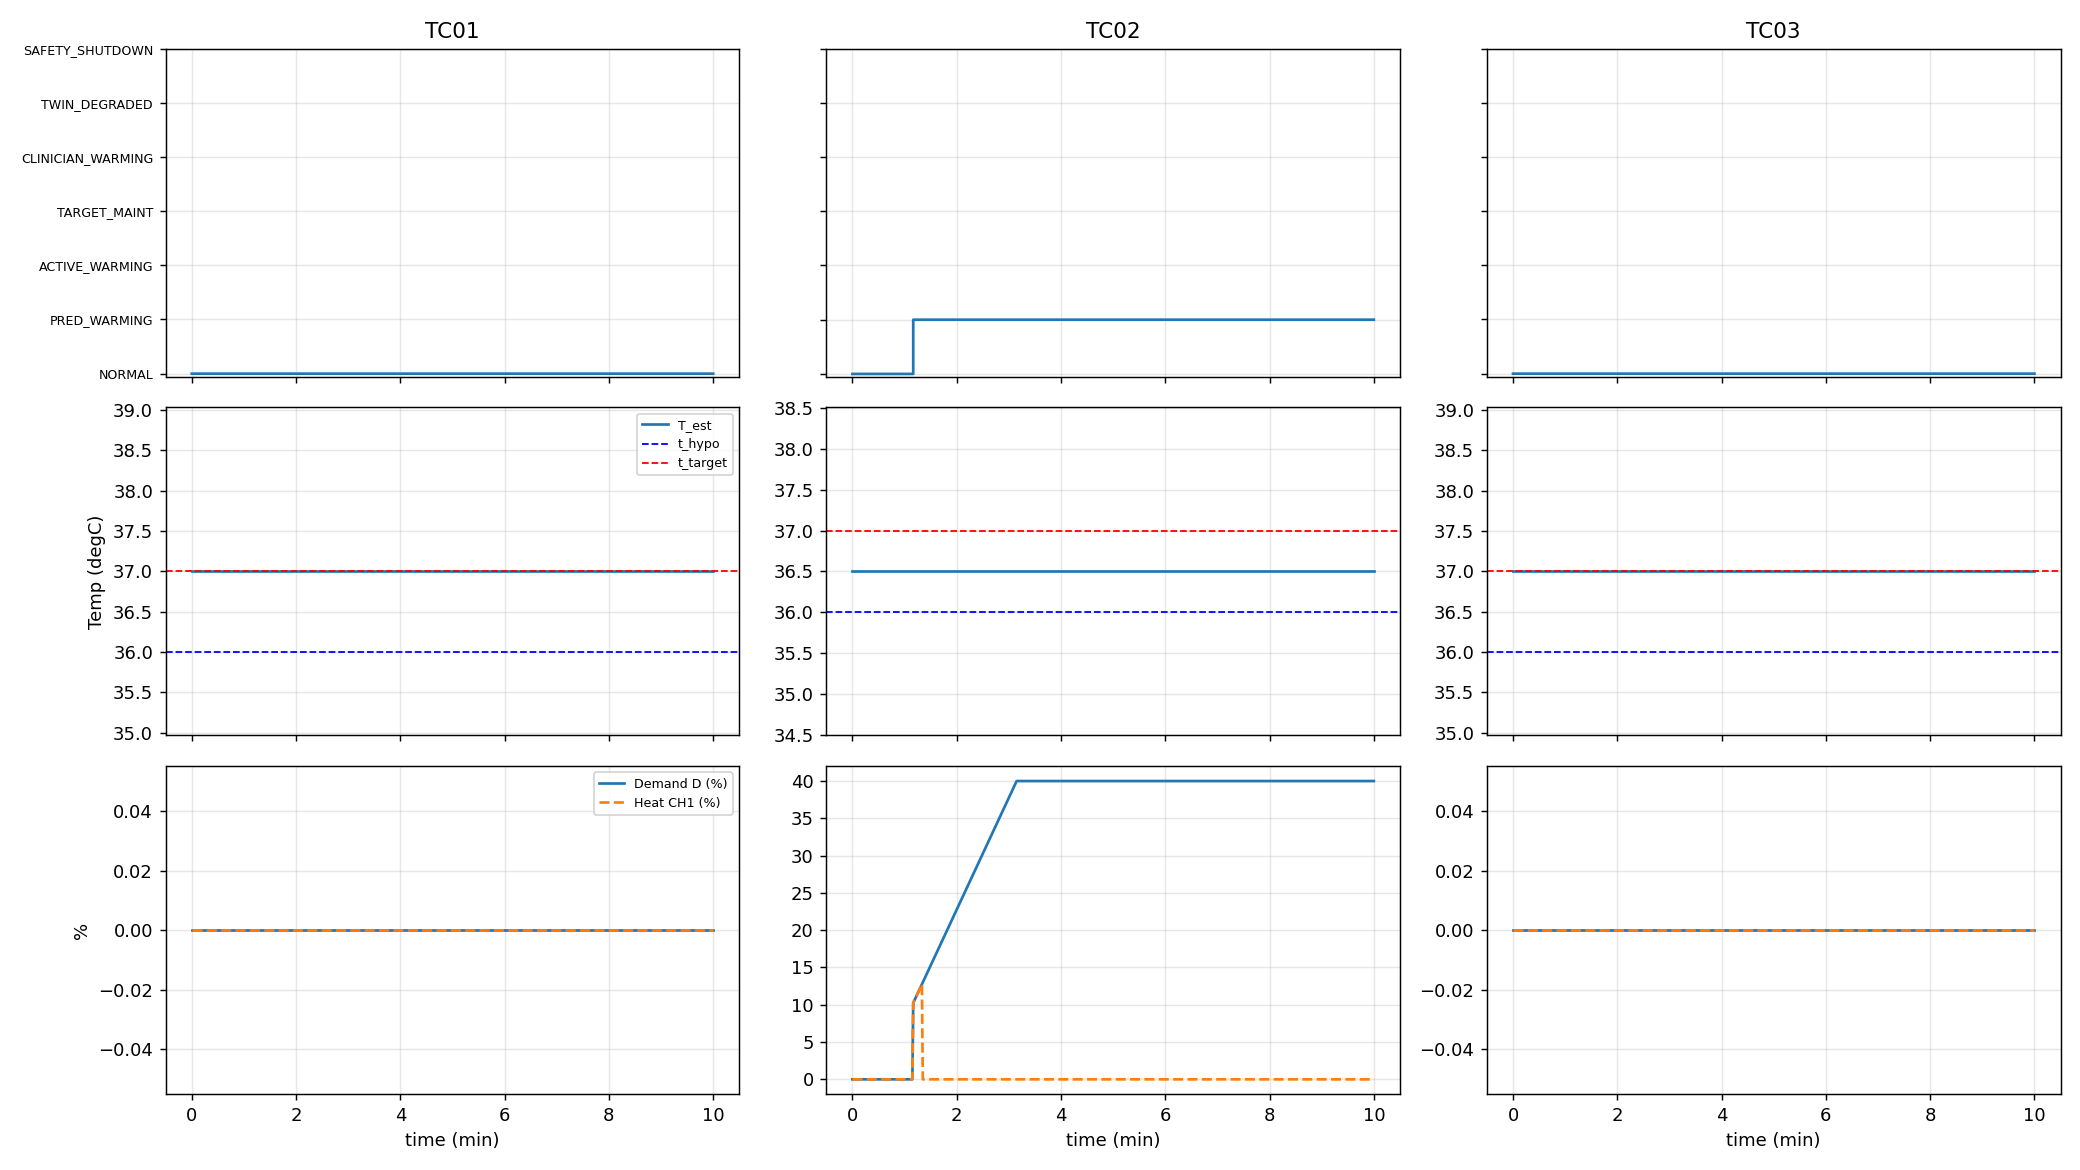

closed_loop_demo.png


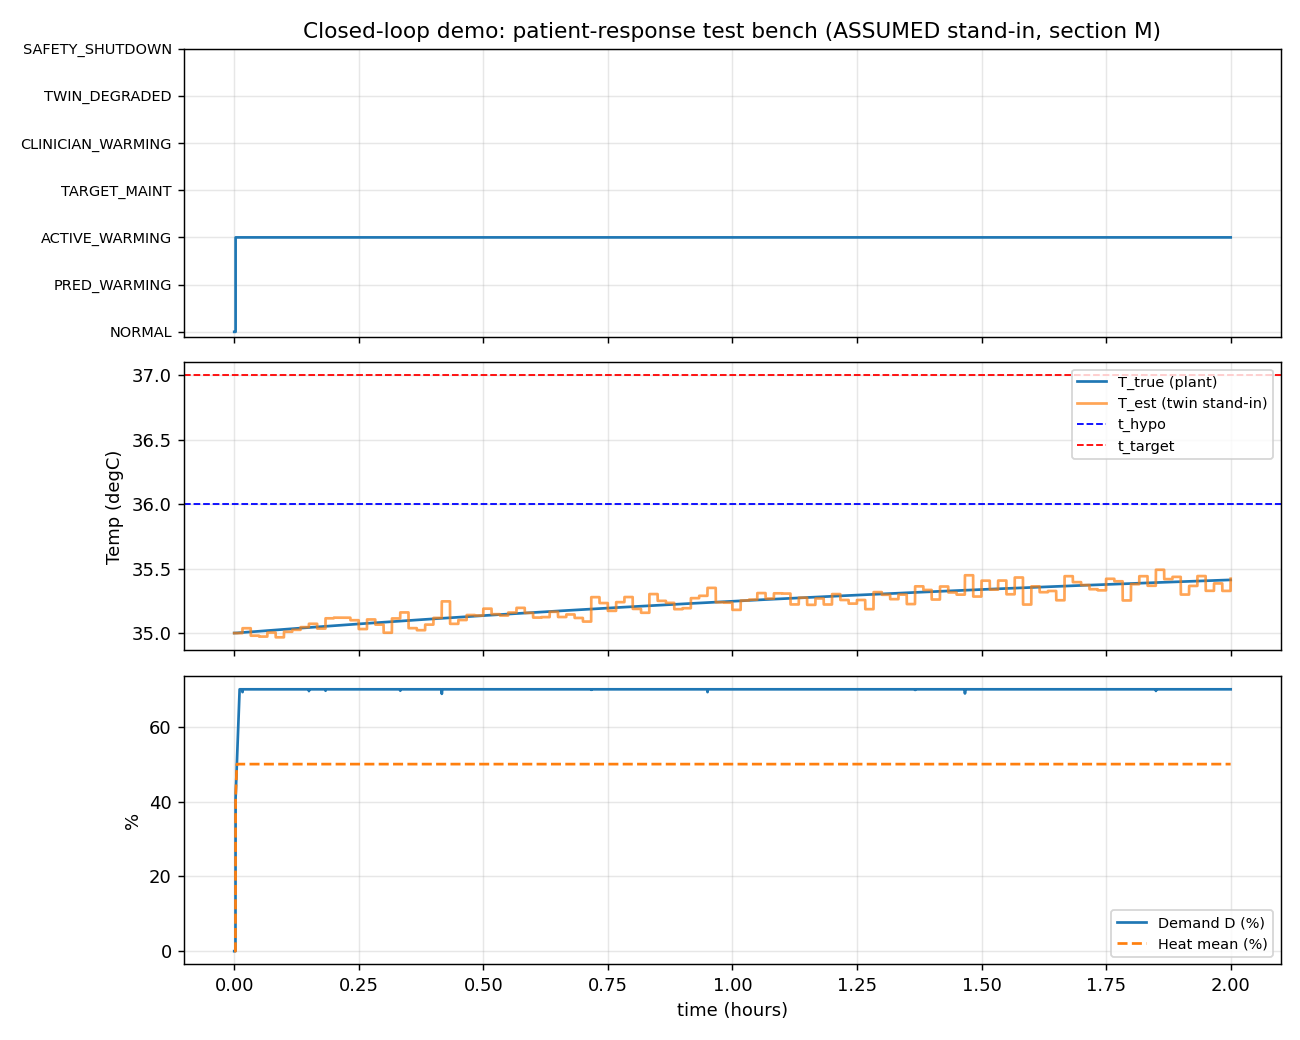

fault_overtemp_demo.png


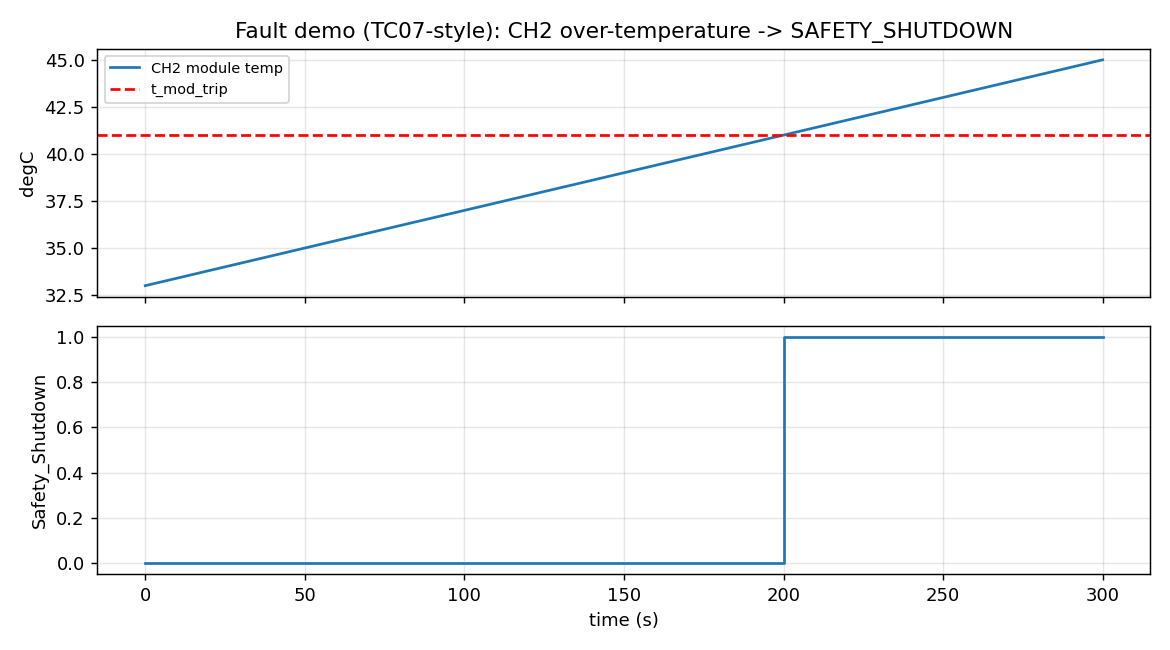

fault_sensor_demo.png


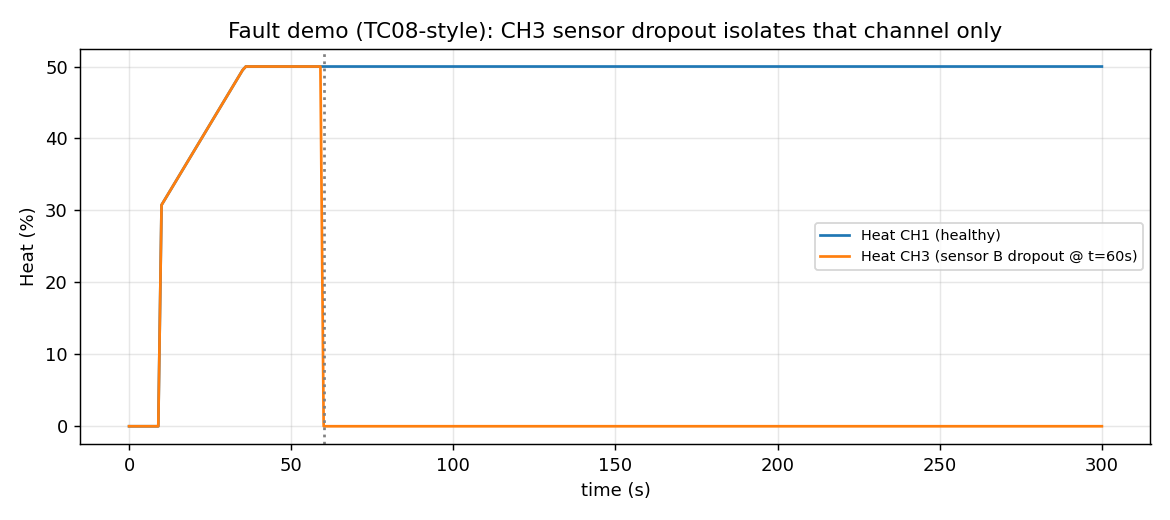

In [ ]:
from IPython.display import Image, display
import os

for f in sorted(os.listdir(RESULTS_DIR)):
    if f.endswith('.png'):
        print(f)
        path = os.path.join(RESULTS_DIR, f)
        display(Image(filename=path))

In [ ]:
"""
NERAM integration log exporter - produces integration/controller_logs/
ctrl_<scenario>.csv in the EXACT column order from section S of the plan,
for the scenarios Sai's build_replay.py needs: ctrl_SYN_02, ctrl_TC04,
ctrl_TC05, ctrl_TC07, ctrl_TC08, ctrl_TC13. Also implements TC04 (closed-
loop recovery), TC05 (clinician early start) and TC13 (twin degraded) as
real, assertion-based tests per section N - these were not in run_tests.py.

Run after the main script (reuses P, Controller, PatientPlant, ModuleThermal,
TwinStandin, RESULTS_DIR already defined there).
"""
import csv
import os
import numpy as np

LOG_DIR = 'integration_logs'
os.makedirs(LOG_DIR, exist_ok=True)

# Exact column order, section S
CTRL_LOG_COLUMNS = (
    ['t_s', 'Controller_State', 'Degraded_Substate'] +
    [f'Heat_{i}' for i in range(1, 5)] +
    ['Demand_Global', 'Trigger_Reason', 'Alert', 'Safety_Shutdown', 'Fault_Latched', 'fault_code'] +
    [f'Channel_Fault_{i}' for i in range(1, 5)] +
    ['Data_Stale_Twin', 'Data_Stale_HW', 'Clinician_Mode'] +
    [f'Module_Temp_{i}_A' for i in range(1, 5)] +  # interleaved per spec note "Module_Temp_1_A, 1_B, ..."
    [f'Module_Temp_{i}_B' for i in range(1, 5)] +
    [f'Module_Connected_{i}' for i in range(1, 5)] +
    [f'Heater_Current_{i}' for i in range(1, 5)] +
    [f'HW_Cutoff_{i}' for i in range(1, 5)] +
    ['HW_Heartbeat_s', 'HW_Fault_Code', 'T_plant', 'dT_heat', 'plant_mode']
)


def nan_to_cell(v):
    if isinstance(v, bool):
        return int(v)
    if isinstance(v, float) and np.isnan(v):
        return ''
    return v


def write_ctrl_log(scenario_name, rows):
    """rows: list of dicts, each with every key in CTRL_LOG_COLUMNS."""
    path = os.path.join(LOG_DIR, f'ctrl_{scenario_name}.csv')
    with open(path, 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(CTRL_LOG_COLUMNS)
        for r in rows:
            w.writerow([nan_to_cell(r[c]) for c in CTRL_LOG_COLUMNS])
    print(f"wrote {path} ({len(rows)} rows)")


def make_row(t_s, out, sig, T_plant=float('nan'), dT_heat=float('nan'), plant_mode='OPEN_LOOP'):
    row = dict(t_s=t_s, Controller_State=out['sup_Controller_State'],
               Degraded_Substate=out['sup_Degraded_Substate'],
               Demand_Global=out['D'], Trigger_Reason=out['sup_Trigger_Reason'],
               Alert=out['sup_Alert'], Safety_Shutdown=out['sup_Safety_Shutdown'],
               Fault_Latched=out['fault_Fault_Latched'], fault_code=out['fault_fault_code'],
               Data_Stale_Twin=out['twin_Data_Stale_Twin'], Data_Stale_HW=out['fault_Data_Stale_HW'],
               Clinician_Mode=out['sup_Clinician_Mode'],
               HW_Heartbeat_s=sig['HW_Heartbeat_s'], HW_Fault_Code=sig['HW_Fault_Code'],
               T_plant=T_plant, dT_heat=dT_heat, plant_mode=plant_mode)
    for i in range(4):
        row[f'Heat_{i+1}'] = out['Heat'][i]
        row[f'Channel_Fault_{i+1}'] = out['fault_Channel_Fault'][i]
        row[f'Module_Temp_{i+1}_A'] = sig['Module_Temp_A'][i]
        row[f'Module_Temp_{i+1}_B'] = sig['Module_Temp_B'][i]
        row[f'Module_Connected_{i+1}'] = sig['Module_Connected'][i]
        row[f'Heater_Current_{i+1}'] = sig['Heater_Current'][i]
        row[f'HW_Cutoff_{i+1}'] = sig['HW_Cutoff'][i]
    return row


# ---------------------------------------------------------------------------
# TC02 -> ctrl_SYN_02.csv (open loop, re-run with full logging)
# ---------------------------------------------------------------------------
def run_and_log_tc02():
    ctrl = Controller(P)
    sig = default_signals()
    sig.update(T_est=36.5, T_obs=36.5, T_pred_20=35.5, T_pred_30=35.8, T_pred_60=36.2,
               P_below_hypo_20=0.35, P_below_hypo_30=0.10, P_below_hypo_60=0.10)
    rows = []
    for k in range(601):
        t_s = k * P['ts_ctrl_s']
        sig['T_twin_s'] = (t_s // P['ts_twin_s']) * P['ts_twin_s']
        sig['HW_Heartbeat_s'] = t_s
        out = ctrl.step(t_s, sig)
        rows.append(make_row(t_s, out, sig, plant_mode='OPEN_LOOP'))
    write_ctrl_log('SYN_02', rows)
    return rows


# ---------------------------------------------------------------------------
# TC04: Active recovery to target (STANDIN closed loop, start below t_hypo)
# ---------------------------------------------------------------------------
def run_and_log_tc04(duration_s=14400):
    ctrl = Controller(P)
    plant = PatientPlant(P, T0=35.0)
    modules = ModuleThermal(P)
    twin = TwinStandin(P)
    sig = default_signals()
    rows = []
    Heat = [0.0] * 4
    reached_active = False
    reached_maint = False
    max_heat_in_maint = 0.0
    shutdown_seen = False

    for k in range(int(duration_s / P['ts_ctrl_s']) + 1):
        t_s = k * P['ts_ctrl_s']
        T_true = plant.step(Heat, P['ts_ctrl_s'])
        A, B = modules.step(Heat, P['ts_ctrl_s'])
        tw = twin.step(t_s, T_true)
        Heater_Current = [P['i_on_A'] * h / 100.0 for h in Heat]

        sig.update(T_twin_s=tw['T_twin_s'], T_est=tw['T_est'], T_obs=tw['T_obs'],
                   T_est_sd=tw['T_est_sd'], Module_Temp_A=A, Module_Temp_B=B,
                   HW_Heartbeat_s=t_s, Heater_Current=Heater_Current,
                   T_pred_20=tw['T_est'] - 0.3, T_pred_30=tw['T_est'] - 0.2, T_pred_60=tw['T_est'],
                   P_below_hypo_20=0.4 if tw['T_est'] < P['t_hypo_degC'] + 0.5 else 0.05,
                   P_below_hypo_30=0.2, P_below_hypo_60=0.1)

        out = ctrl.step(t_s, sig)
        Heat = out['Heat']
        state = out['sup_Controller_State']
        if state == 2:
            reached_active = True
        if state == 3:
            reached_maint = True
            max_heat_in_maint = max(max_heat_in_maint, max(Heat))
        if out['sup_Safety_Shutdown']:
            shutdown_seen = True

        rows.append(make_row(t_s, out, sig, T_plant=T_true, dT_heat=T_true - plant.baseline,
                              plant_mode='STANDIN'))

    write_ctrl_log('TC04', rows)

    pass_tc04 = reached_active and reached_maint and (not shutdown_seen) and \
                (max_heat_in_maint <= P['d_maint_max_pct'])
    print(f"TC04: reached ACTIVE={reached_active}, reached TARGET_MAINTENANCE={reached_maint}, "
          f"shutdown={shutdown_seen}, max_heat_in_maint={max_heat_in_maint:.1f}% "
          f"(cap {P['d_maint_max_pct']}%) -> {'PASS' if pass_tc04 else 'FAIL'}")
    if not reached_maint:
        print("  NOTE: with the current placeholder plant gain (k_heat_degC_per_h="
              f"{P['k_heat_degC_per_h']}) and channel cap ({P['p_max_ch_pct'][0]}%), "
              f"the patient asymptotes well below t_target_degC={P['t_target_degC']} and "
              "never reaches TARGET_MAINTENANCE in this run. This is a real result, not a "
              "bug - it means these TBD placeholder values can't demonstrate TC04's required "
              "transition. Flag to Sai/Shreehan: TC04 needs real k_heat_degC_per_h / "
              "p_max_ch_pct before it can genuinely pass.")
    return pass_tc04


# ---------------------------------------------------------------------------
# TC05: Clinician early start (SYN_01, Clinician_Start at 600s)
# ---------------------------------------------------------------------------
def run_and_log_tc05(duration_s=900):
    ctrl = Controller(P)
    sig = default_signals()  # SYN_01 = healthy stable baseline
    rows = []
    entered_at = None
    for k in range(int(duration_s / P['ts_ctrl_s']) + 1):
        t_s = k * P['ts_ctrl_s']
        sig['T_twin_s'] = (t_s // P['ts_twin_s']) * P['ts_twin_s']
        sig['HW_Heartbeat_s'] = t_s
        sig['Clinician_Start'] = 1 if t_s >= 600 else 0

        out = ctrl.step(t_s, sig)
        if out['sup_Controller_State'] == 4 and entered_at is None:
            entered_at = t_s
        rows.append(make_row(t_s, out, sig, plant_mode='OPEN_LOOP'))

    write_ctrl_log('TC05', rows)
    pass_tc05 = entered_at is not None and entered_at <= 601
    print(f"TC05: CLINICIAN_WARMING entered at t={entered_at}s (need <=601s) -> "
          f"{'PASS' if pass_tc05 else 'FAIL'}")
    return pass_tc05


# ---------------------------------------------------------------------------
# TC13: Twin unreliable - no autonomous warming (SYN_04)
# ---------------------------------------------------------------------------
def run_and_log_tc13(duration_s=900):
    ctrl = Controller(P)
    sig = default_signals()
    sig.update(P_below_hypo_20=0.35, P_below_hypo_30=0.10)
    rows = []
    monitor_seen = False
    any_heat_during_degraded = False
    normal_after = None
    for k in range(int(duration_s / P['ts_ctrl_s']) + 1):
        t_s = k * P['ts_ctrl_s']
        sig['T_twin_s'] = (t_s // P['ts_twin_s']) * P['ts_twin_s']
        sig['HW_Heartbeat_s'] = t_s
        if 300 <= t_s < 600:
            sig['Twin_Valid'] = 3  # DEGRADED
        else:
            sig['Twin_Valid'] = 2  # VALID

        out = ctrl.step(t_s, sig)
        state, substate = out['sup_Controller_State'], out['sup_Degraded_Substate']
        if state == 5 and substate == 1:
            monitor_seen = True
            if max(out['Heat']) > 0:
                any_heat_during_degraded = True
        if t_s >= 600 and state == 0 and normal_after is None:
            normal_after = t_s
        rows.append(make_row(t_s, out, sig, plant_mode='OPEN_LOOP'))

    write_ctrl_log('TC13', rows)
    pass_tc13 = monitor_seen and (not any_heat_during_degraded) and normal_after is not None
    print(f"TC13: entered TWIN_DEGRADED.MONITOR={monitor_seen}, any heat while degraded="
          f"{any_heat_during_degraded}, back to NORMAL at t={normal_after}s -> "
          f"{'PASS' if pass_tc13 else 'FAIL'}")
    return pass_tc13


# ---------------------------------------------------------------------------
# TC07 / TC08 -> ctrl_TC07.csv, ctrl_TC08.csv (re-run fault demos with full logging)
# ---------------------------------------------------------------------------
def run_and_log_tc07(duration_s=300):
    ctrl = Controller(P)
    sig = default_signals()
    rows = []
    for k in range(int(duration_s / P['ts_ctrl_s']) + 1):
        t_s = k * P['ts_ctrl_s']
        sig['T_twin_s'] = (t_s // P['ts_twin_s']) * P['ts_twin_s']
        sig['HW_Heartbeat_s'] = t_s
        ramp_temp = 33 + (45 - 33) * min(1.0, t_s / duration_s)
        A = list(sig['Module_Temp_A']); B = list(sig['Module_Temp_B'])
        A[1] = ramp_temp; B[1] = ramp_temp
        sig['Module_Temp_A'], sig['Module_Temp_B'] = A, B
        out = ctrl.step(t_s, sig)
        rows.append(make_row(t_s, out, sig, plant_mode='STANDIN'))
    write_ctrl_log('TC07', rows)


def run_and_log_tc08(duration_s=300):
    ctrl = Controller(P)
    sig = default_signals()
    sig.update(T_est=35.5, T_obs=35.5, P_below_hypo_20=0.35, P_below_hypo_30=0.10)
    rows = []
    for k in range(int(duration_s / P['ts_ctrl_s']) + 1):
        t_s = k * P['ts_ctrl_s']
        sig['T_twin_s'] = (t_s // P['ts_twin_s']) * P['ts_twin_s']
        sig['HW_Heartbeat_s'] = t_s
        sig['Heater_Current'] = [P['i_on_A'] * h / 100.0 for h in ctrl.Heat_prev]
        if t_s >= 60:
            B = list(sig['Module_Temp_B']); B[2] = float('nan'); sig['Module_Temp_B'] = B
        out = ctrl.step(t_s, sig)
        rows.append(make_row(t_s, out, sig, plant_mode='STANDIN'))
    write_ctrl_log('TC08', rows)


if True:
    run_and_log_tc02()
    tc04_pass = run_and_log_tc04()
    tc05_pass = run_and_log_tc05()
    tc13_pass = run_and_log_tc13()
    run_and_log_tc07()
    run_and_log_tc08()

    with open(os.path.join(RESULTS_DIR, 'test_results_extended.csv'), 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['tc_id', 'title', 'result', 'notes'])
        w.writerow(['TC04', 'Active recovery to target', 'PASS' if tc04_pass else 'FAIL',
                    'see console note if FAIL - placeholder plant gain likely insufficient'])
        w.writerow(['TC05', 'Clinician early start', 'PASS' if tc05_pass else 'FAIL', ''])
        w.writerow(['TC13', 'Twin unreliable - no autonomous warming', 'PASS' if tc13_pass else 'FAIL', ''])

    print(f"\nctrl_<scenario>.csv files are in ./{LOG_DIR}/ - hand these to Sai.")
    print("NOTE: still using placeholder params.json values (t_target_degC, t_hypo_degC, "
          "hardware thresholds). Swap in the real config/params.json the moment Sai/Shreehan "
          "deliver it, then re-run this whole script before the final handoff.")

wrote integration_logs/ctrl_SYN_02.csv (601 rows)
wrote integration_logs/ctrl_TC04.csv (14401 rows)
TC04: reached ACTIVE=True, reached TARGET_MAINTENANCE=False, shutdown=False, max_heat_in_maint=0.0% (cap 50%) -> FAIL
  NOTE: with the current placeholder plant gain (k_heat_degC_per_h=0.6) and channel cap (50%), the patient asymptotes well below t_target_degC=37.0 and never reaches TARGET_MAINTENANCE in this run. This is a real result, not a bug - it means these TBD placeholder values can't demonstrate TC04's required transition. Flag to Sai/Shreehan: TC04 needs real k_heat_degC_per_h / p_max_ch_pct before it can genuinely pass.
wrote integration_logs/ctrl_TC05.csv (901 rows)
TC05: CLINICIAN_WARMING entered at t=600s (need <=601s) -> PASS
wrote integration_logs/ctrl_TC13.csv (901 rows)
TC13: entered TWIN_DEGRADED.MONITOR=True, any heat while degraded=False, back to NORMAL at t=630s -> PASS
wrote integration_logs/ctrl_TC07.csv (301 rows)
wrote integration_logs/ctrl_TC08.csv (301 rows)

c

In [ ]:
import shutil
from google.colab import files

shutil.make_archive('neram_integration_logs', 'zip', '.', 'integration_logs')
files.download('neram_integration_logs.zip')
files.download('results/test_results_extended.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>